In [2]:
import numpy as np
import matplotlib.pyplot as plt
import astropy
import lightkurve as lk
import warnings
warnings.filterwarnings('ignore')
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Astropy:", astropy.__version__)
print("Lightkurve:", lk.__version__)

NumPy: 2.4.2
Matplotlib: 3.10.8
Astropy: 8.0.1
Lightkurve: 2.6.0


In [3]:
# Ищем данные TESS для звезды HAT-P-7
search_result = lk.search_lightcurve('HAT-P-7')
print(f"Найдено записей: {len(search_result)}")
search_result

Найдено записей: 125


#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 00,2009,Kepler,60,kplr010666592,0.0
1,Kepler Quarter 01,2009,Kepler,60,kplr010666592,0.0
2,Kepler Quarter 02,2009,Kepler,60,kplr010666592,0.0
3,Kepler Quarter 02,2009,Kepler,60,kplr010666592,0.0
4,Kepler Quarter 02,2009,Kepler,60,kplr010666592,0.0
5,Kepler Quarter 03,2009,Kepler,60,kplr010666592,0.0
6,Kepler Quarter 03,2009,Kepler,60,kplr010666592,0.0
7,Kepler Quarter 03,2009,Kepler,60,kplr010666592,0.0
8,Kepler Quarter 00,2009,Kepler,1800,kplr010666592,0.0


In [4]:
# Выбираем TESS Sector 14, SPOC, 120s (строка 67 из таблицы)
# Индексация с нуля: search_result[67]
lc = search_result[67].download()

# Смотрим, что скачали
print(f"Звезда: {lc.targetid}")
print(f"Время наблюдений: {lc.time.min()} до {lc.time.max()}")
print(f"Количество точек: {len(lc)}")
print(f"Средний поток: {lc.flux.mean():.2f}")

Звезда: 424865156
Время наблюдений: 1683.35599597146 до 1710.2060490690258
Количество точек: 18420
Средний поток: 15341.81 electron / s


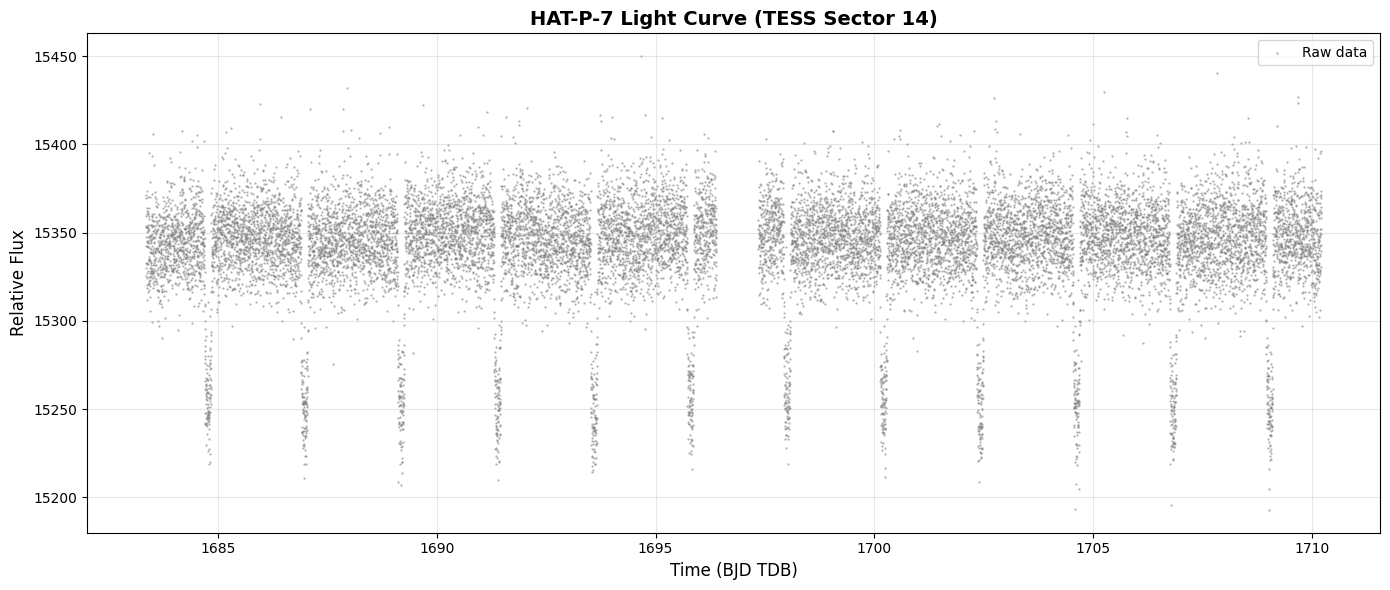

In [6]:
# Извлекаем обычные числа из astropy-объектов
time = lc.time.value    # числа (BJD TDB)
flux = lc.flux.value    # числа (относительный поток)

fig, ax = plt.subplots(figsize=(14, 6))
ax.scatter(time, flux, s=0.5, alpha=0.5, color='gray', label='Raw data')

ax.set_xlabel('Time (BJD TDB)', fontsize=12)
ax.set_ylabel('Relative Flux', fontsize=12)
ax.set_title('HAT-P-7 Light Curve (TESS Sector 14)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

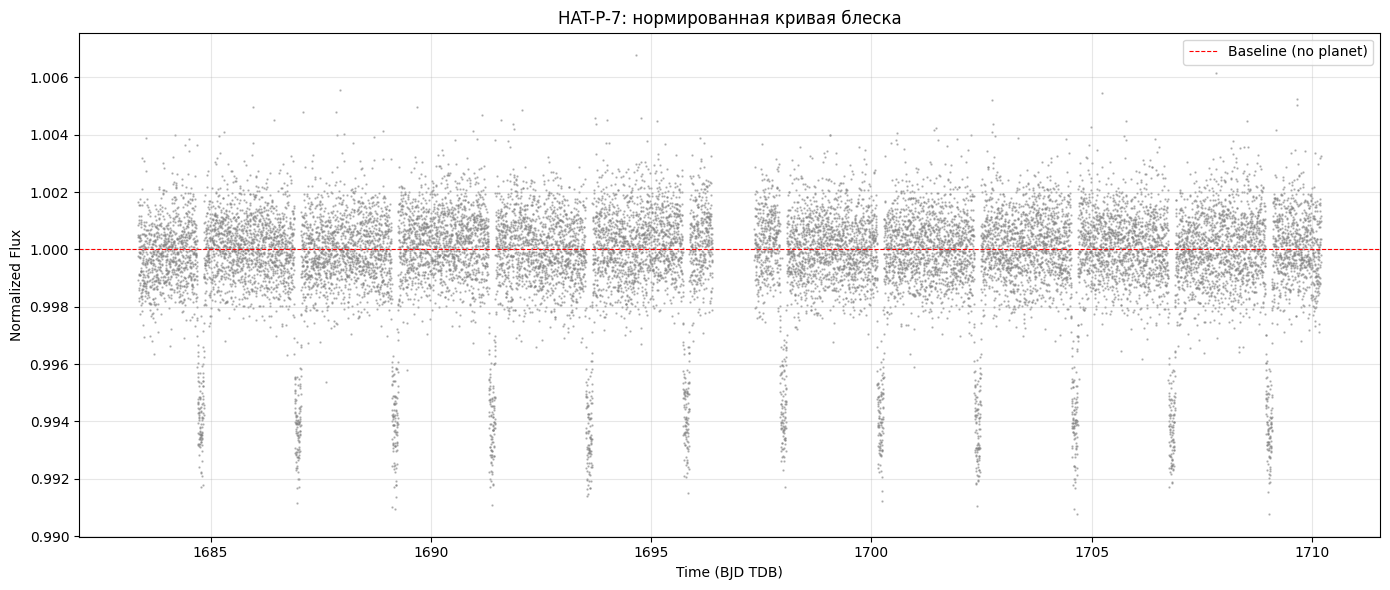

In [7]:
# 1. Убираем NaN и выбросы (космические лучи, сбои детектора)
clean = lc.remove_nans().remove_outliers(sigma=5)

time = clean.time.value
flux = clean.flux.value

# 2. Нормируем: делим на медиану -> поток станет ~1.0
flux_norm = flux / np.median(flux)

fig, ax = plt.subplots(figsize=(14, 6))
ax.scatter(time, flux_norm, s=0.5, alpha=0.5, color='gray')
ax.axhline(1.0, color='red', ls='--', lw=0.8, label='Baseline (no planet)')
ax.set_xlabel('Time (BJD TDB)')
ax.set_ylabel('Normalized Flux')
ax.set_title('HAT-P-7: нормированная кривая блеска')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

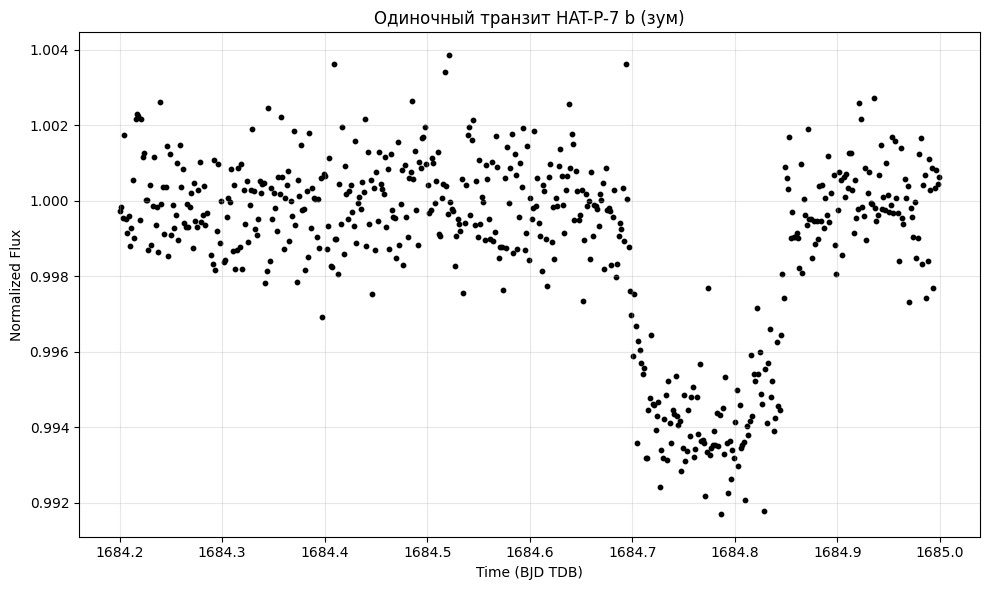

In [8]:
# Первый транзит около 1684.6
mask = (time > 1684.2) & (time < 1685.0)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(time[mask], flux_norm[mask], s=10, color='black')
ax.set_xlabel('Time (BJD TDB)')
ax.set_ylabel('Normalized Flux')
ax.set_title('Одиночный транзит HAT-P-7 b (зум)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
import numpy as np

# Кандидаты на длительность транзита, в сутках
durations = np.array([0.05, 0.1, 0.15, 0.2, 0.3])

bls = lc.to_periodogram(
    method='bls',
    minimum_period=0.5,
    maximum_period=10.0,
    duration=durations          # <-- исправлено
)
depth_electron = bls.depth_at_max_power.value  # 90.36 e-/s
median_flux = np.median(clean.flux.value)       # ~15350 e-/s
depth_fraction = depth_electron / median_flux
print(f"Глубина в долях: {depth_fraction:.6f}")
print(f"Глубина в процентах: {depth_fraction * 100:.3f}%")
print("Найденный период:", bls.period_at_max_power)
print("Найденная длительность:", bls.duration_at_max_power)
print("Найденная глубина:", bls.depth_at_max_power)

Глубина в долях: 0.005888
Глубина в процентах: 0.589%
Найденный период: 2.205671719294601 d
Найденная длительность: 0.15 d
Найденная глубина: 90.36307919484017 electron / s


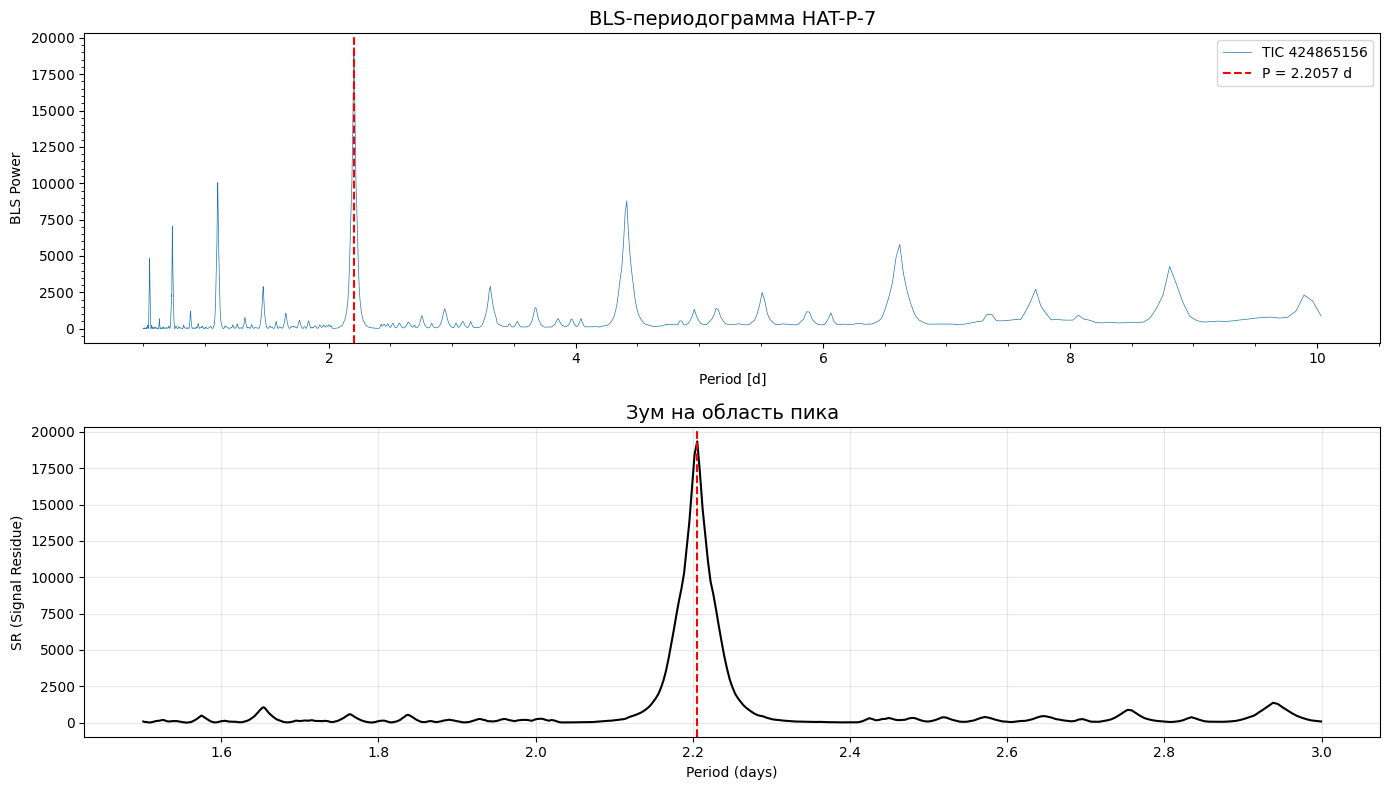

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

bls.plot(ax=axes[0])
axes[0].set_title('BLS-периодограмма HAT-P-7', fontsize=14)
axes[0].axvline(bls.period_at_max_power.value, color='red', ls='--',
                label=f'P = {bls.period_at_max_power.value:.4f} d')
axes[0].legend()

periods = bls.period.value
power = bls.power.value
mask = (periods > 1.5) & (periods < 3.0)
axes[1].plot(periods[mask], power[mask], color='black')
axes[1].axvline(bls.period_at_max_power.value, color='red', ls='--')
axes[1].set_xlabel('Period (days)')
axes[1].set_ylabel('SR (Signal Residue)')
axes[1].set_title('Зум на область пика', fontsize=14)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

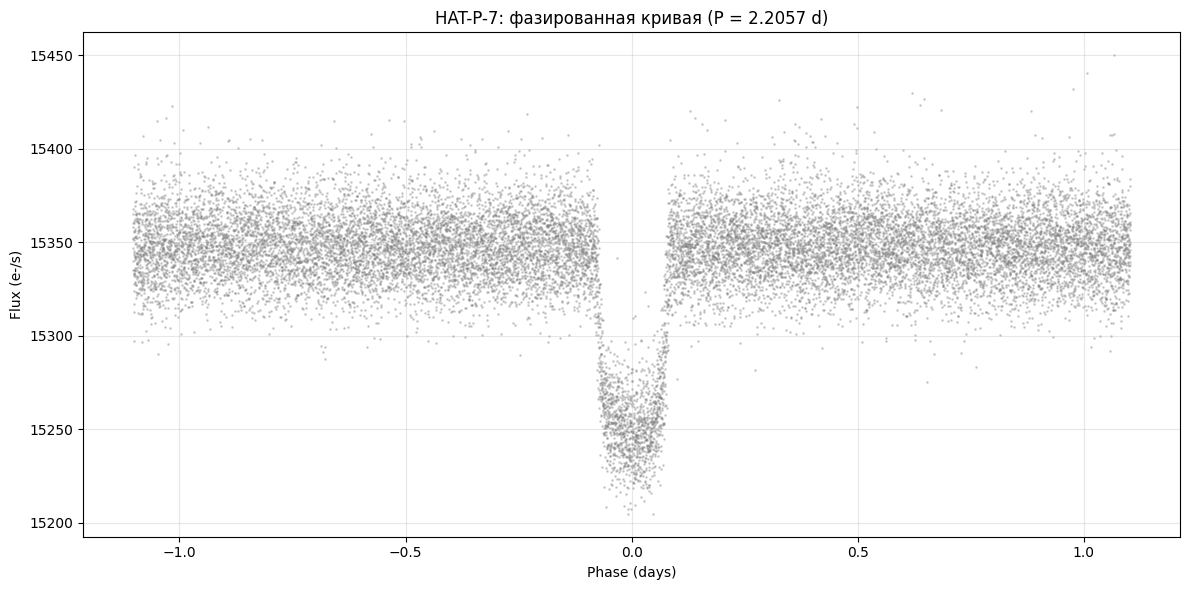

In [19]:
# Фазирование по найденному периоду
period = bls.period_at_max_power
lc_folded = clean.fold(period=period, epoch_time=bls.transit_time_at_max_power)

# График фазированной кривой
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(lc_folded.phase.value, lc_folded.flux.value, 
           s=1, alpha=0.3, color='gray')
ax.set_xlabel('Phase (days)')
ax.set_ylabel('Flux (e-/s)')
ax.set_title(f'HAT-P-7: фазированная кривая (P = {period.value:.4f} d)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

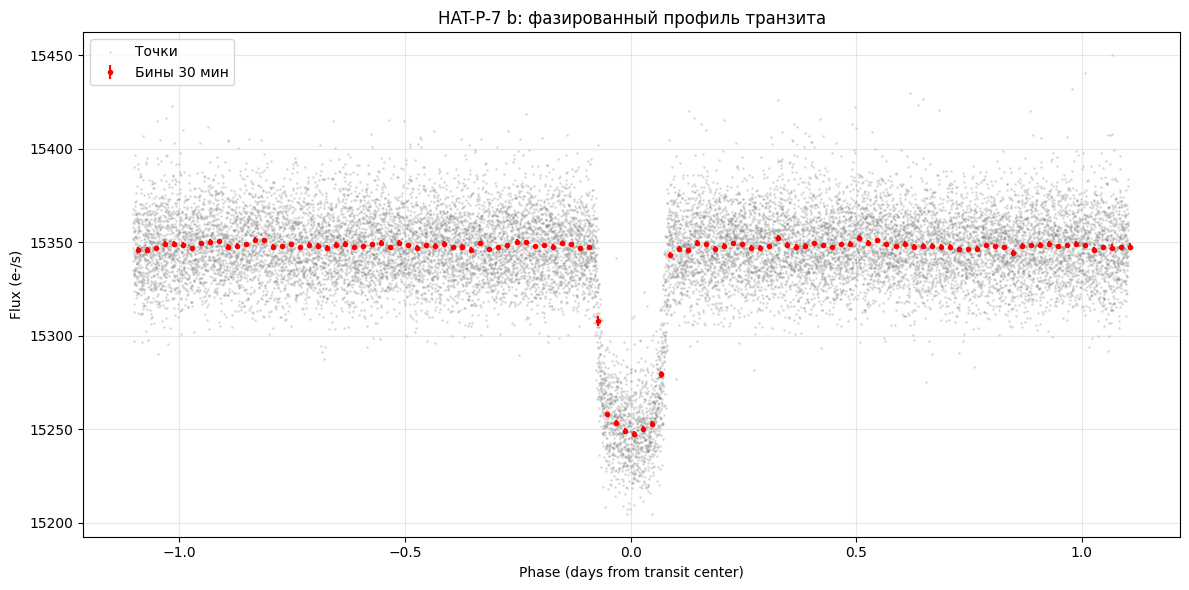

In [20]:
# 1. Правильное фазирование: ноль фазы = центр транзита
t0 = bls.transit_time_at_max_power
lc_folded = clean.fold(period=bls.period_at_max_power, epoch_time=t0)

phase = lc_folded.phase.value
flux = lc_folded.flux.value

# 2. Биннинг по 30 минут (0.02 суток)
bin_size = 0.02
bins = np.arange(phase.min(), phase.max() + bin_size, bin_size)
idx = np.digitize(phase, bins)   # номер корзины для каждой точки

bin_c, bin_f, bin_e = [], [], []
for i in range(1, len(bins)):
    sel = (idx == i)
    if sel.sum() >= 5:                      # корзины с <5 точек пропускаем
        bin_c.append(bins[i-1] + bin_size/2)          # центр корзины
        bin_f.append(flux[sel].mean())                 # среднее в корзине
        bin_e.append(flux[sel].std()/np.sqrt(sel.sum()))  # ошибка среднего

bin_c = np.array(bin_c); bin_f = np.array(bin_f); bin_e = np.array(bin_e)

# 3. График: серые точки + красные бины
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(phase, flux, s=1, alpha=0.2, color='gray', label='Точки')
ax.errorbar(bin_c, bin_f, yerr=bin_e, fmt='o', ms=3, color='red',
            label='Бины 30 мин')
ax.set_xlabel('Phase (days from transit center)')
ax.set_ylabel('Flux (e-/s)')
ax.set_title('HAT-P-7 b: фазированный профиль транзита')
ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [21]:
baseline = np.median(bin_f[np.abs(bin_c) > 0.3])   # вне транзита
bottom   = np.mean(bin_f[np.abs(bin_c) < 0.06])    # плоское дно
depth    = (baseline - bottom) / baseline

print(f"Базовая линия: {baseline:.1f} e-/s")
print(f"Дно транзита:  {bottom:.1f} e-/s")
print(f"Глубина: {depth*100:.3f}%  (литература: ~0.65%)")

Базовая линия: 15348.2 e-/s
Дно транзита:  15251.9 e-/s
Глубина: 0.628%  (литература: ~0.65%)


In [23]:
import astropy.units as u
import astropy.constants as const

# Параметры звезды из литературы
R_star = 1.84 * u.R_sun
M_star = 1.47 * u.M_sun
T_eff  = 6350 * u.K

# Наши измерения
depth = 0.00628
P = bls.period_at_max_power.to(u.day)

# 1. Радиус планеты
R_planet = R_star * np.sqrt(depth)
print("Радиус планеты:", R_planet.to(u.R_jup).round(3),
      "=", R_planet.to(u.R_earth).round(2))

# 2. Большая полуось (третий закон Кеплера)
a = (const.G * M_star * P**2 / (4 * np.pi**2))**(1/3)
print("Большая полуось:", a.to(u.AU).round(4))

# 3. Равновесная температура для двух альбедо
for A in [0.0, 0.3]:
    T_eq = T_eff * np.sqrt(R_star / (2 * a)) * (1 - A)**0.25
    print(f"Альбедо A={A}: T_eq = {T_eq.to(u.K):.0f}")

Радиус планеты: 1.419 jupiterRad = 15.9 earthRad
Большая полуось: 0.0377 AU
Альбедо A=0.0: T_eq = 2139 K
Альбедо A=0.3: T_eq = 1957 K


In [24]:
import pandas as pd

# Создаём таблицу из бинов
df_bins = pd.DataFrame({
    'phase_days': bin_c,
    'flux_e_s': bin_f,
    'flux_err_e_s': bin_e
})

# Сохраняем в CSV
df_bins.to_csv('data/hatp7_phase_binned.csv', index=False)
print("Сохранено: data/hatp7_phase_binned.csv")
print(df_bins.head())

OSError: Cannot save file into a non-existent directory: 'data'